In [1]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append("..")


In [2]:
import os
import sys

sys.path.append("../")

##################################################################
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["CUDA_VISIBLE_DEVICES"] = "3,4,5,6,7"
##################################################################

import logging
import torch
import transformers

from rich.console import Console
from rich.theme import Theme

from src.utils import logging_utils
from src.utils import env_utils
import seaborn as sns

custom_theme = Theme({"default": "white"})
console = Console(theme=custom_theme)


def rich_print(*args, **kwargs):
    console.print(*args, **kwargs)


logger = logging.getLogger(__name__)

logging.basicConfig(
    level=logging.DEBUG,
    format=logging_utils.DEFAULT_FORMAT,
    datefmt=logging_utils.DEFAULT_DATEFMT,
    stream=sys.stdout,
)

logger.info(f"{torch.__version__=}, {torch.version.cuda=}")
logger.info(
    f"{torch.cuda.is_available()=}, {torch.cuda.device_count()=}, {torch.cuda.get_device_name()=}"
)
logger.info(f"{transformers.__version__=}")

2026-04-09 14:49:09 __main__ INFO     torch.__version__='2.6.0+cu124', torch.version.cuda='12.4'
2026-04-09 14:49:10 __main__ INFO     torch.cuda.is_available()=True, torch.cuda.device_count()=5, torch.cuda.get_device_name()='NVIDIA A100-SXM4-80GB'
2026-04-09 14:49:10 __main__ INFO     transformers.__version__='5.3.0'


In [3]:
from src.models import ModelandTokenizer

MODEL_NAME = "Qwen/Qwen2.5-Coder-32B-Instruct"
# MODEL_NAME = "meta-llama/Llama-3.3-70B-Instruct"

mt = ModelandTokenizer(
    model_key=MODEL_NAME,
    dtype=torch.bfloat16,
    device_map="auto",
    attn_implementation="eager",
)
print(f"n_layer={mt.n_layer}, n_embd={mt.n_embd}, n_heads={mt.model.config.num_attention_heads}")
print(f"head_dim={mt.n_embd // mt.model.config.num_attention_heads}")
print(f"attn_module_name_format={mt.attn_module_name_format!r}")

2026-04-09 14:49:16 src.models WARNING  Qwen/Qwen2.5-Coder-32B-Instruct not found in /disk/u/arnab/Codes/Models
If not found in cache, model will be downloaded from HuggingFace to cache directory
2026-04-09 14:49:16 httpx DEBUG    load_ssl_context verify=True cert=None trust_env=True http2=False
2026-04-09 14:49:16 httpx DEBUG    load_verify_locations cafile='/disk/u/arnab/miniconda3/envs/goals/lib/python3.11/site-packages/certifi/cacert.pem'
2026-04-09 14:49:16 httpcore.connection DEBUG    connect_tcp.started host='huggingface.co' port=443 local_address=None timeout=10 socket_options=None
2026-04-09 14:49:16 httpcore.connection DEBUG    connect_tcp.complete return_value=<httpcore._backends.sync.SyncStream object at 0x7f73ae1b1050>
2026-04-09 14:49:16 httpcore.connection DEBUG    start_tls.started ssl_context=<ssl.SSLContext object at 0x7f73adf897f0> server_hostname='huggingface.co' timeout=10
2026-04-09 14:49:16 httpcore.connection DEBUG    start_tls.complete return_value=<httpcore._b

Loading weights:   0%|          | 0/771 [00:00<?, ?it/s]

2026-04-09 14:49:35 httpcore.connection DEBUG    close.started
2026-04-09 14:49:35 httpcore.connection DEBUG    close.complete
2026-04-09 14:49:35 httpcore.connection DEBUG    connect_tcp.started host='huggingface.co' port=443 local_address=None timeout=10 socket_options=None
2026-04-09 14:49:35 httpcore.connection DEBUG    connect_tcp.complete return_value=<httpcore._backends.sync.SyncStream object at 0x7f73ac85ba90>
2026-04-09 14:49:35 httpcore.connection DEBUG    start_tls.started ssl_context=<ssl.SSLContext object at 0x7f73adf897f0> server_hostname='huggingface.co' timeout=10
2026-04-09 14:49:35 httpcore.connection DEBUG    start_tls.complete return_value=<httpcore._backends.sync.SyncStream object at 0x7f73ac85ac90>
2026-04-09 14:49:35 httpcore.http11 DEBUG    send_request_headers.started request=<Request [b'HEAD']>
2026-04-09 14:49:35 httpcore.http11 DEBUG    send_request_headers.complete
2026-04-09 14:49:35 httpcore.http11 DEBUG    send_request_body.started request=<Request [b'HE

# Well-Known Task Completions — Inspection

Inspect outputs of `scripts/generate_well_known_task_completions.py`.

Each result file is a JSON dict with keys:
- `function_name` — task identifier
- `prompt` — full chat-template prompt sent to the model
- `generation` — raw LM completion


In [4]:
import json
from pathlib import Path
from src.utils.env_utils import DEFAULT_RESULTS_DIR, DEFAULT_DATA_DIR

MODEL_SHORT  = "Qwen2.5-Coder-32B-Instruct"   # change to inspect a different model
ORACLE_SHORT = "claude-sonnet-4-6"              # change to match the oracle used for labeling

RESULTS_DIR = Path(DEFAULT_RESULTS_DIR) / "well-known-tasks" / "generations" / MODEL_SHORT
TASKS_DIR   = Path(DEFAULT_DATA_DIR) / "well-known-tasks"

print(f"Results dir : {RESULTS_DIR}")
print(f"Exists      : {RESULTS_DIR.exists()}")


Results dir : /disk/u/arnab/Codes/Projects/goals/results/well-known-task-generations/Qwen2.5-Coder-32B-Instruct
Exists      : True


In [5]:
results: dict[str, dict] = {}

if RESULTS_DIR.exists():
    for path in sorted(RESULTS_DIR.glob("*.json")):
        with open(path) as f:
            results[path.stem] = json.load(f)

print(f"Loaded {len(results)} generated results")


Loaded 134 generated results


In [6]:
from rich.table import Table

# All available task names
all_tasks = sorted(p.stem for p in TASKS_DIR.glob("*.json"))

generated   = sorted(results.keys())
missing     = [t for t in all_tasks if t not in results]

table = Table(title=f"Coverage — {MODEL_SHORT}", show_lines=False, highlight=False)
table.add_column("Stat", style="bold")
table.add_column("Count", justify="right")
table.add_row("Total tasks available", str(len(all_tasks)))
table.add_row("Generated",            f"[green]{len(generated)}[/green]")
table.add_row("Missing",              f"[red]{len(missing)}[/red]")
rich_print(table)

if missing:
    rich_print(f"\n[red]Missing tasks:[/red] {', '.join(missing)}")


           Coverage —            
   Qwen2.5-Coder-32B-Instruct    
┏━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━┓
┃ Stat                  ┃ Count ┃
┡━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━┩
│ Total tasks available │   134 │
│ Generated             │   134 │
│ Missing               │     0 │
└───────────────────────┴───────┘

2026-04-09 14:49:44 matplotlib.pyplot DEBUG    Loaded backend module://matplotlib_inline.backend_inline version unknown.
2026-04-09 14:49:44 matplotlib.pyplot DEBUG    Loaded backend module://matplotlib_inline.backend_inline version unknown.
2026-04-09 14:49:44 matplotlib.font_manager DEBUG    findfont: Matching sans\-serif:style=normal:variant=normal:weight=normal:stretch=normal:size=10.0.
2026-04-09 14:49:44 matplotlib.font_manager DEBUG    findfont: score(FontEntry(fname='/disk/u/arnab/miniconda3/envs/goals/lib/python3.11/site-packages/matplotlib/mpl-data/fonts/ttf/cmsy10.ttf', name='cmsy10', style='normal', variant='normal', weight=400, stretch='normal', size='scalable')) = 10.05
2026-04-09 14:49:44 matplotlib.font_manager DEBUG    findfont: score(FontEntry(fname='/disk/u/arnab/miniconda3/envs/goals/lib/python3.11/site-packages/matplotlib/mpl-data/fonts/ttf/STIXSizThreeSymReg.ttf', name='STIXSizeThreeSym', style='normal', variant='normal', weight=400, stretch='normal', size='scalab

2026-04-09 14:49:44 matplotlib.font_manager DEBUG    findfont: score(FontEntry(fname='/disk/u/arnab/miniconda3/envs/goals/lib/python3.11/site-packages/matplotlib/mpl-data/fonts/ttf/DejaVuSans-Bold.ttf', name='DejaVu Sans', style='normal', variant='normal', weight=700, stretch='normal', size='scalable')) = 0.33499999999999996
2026-04-09 14:49:44 matplotlib.font_manager DEBUG    findfont: score(FontEntry(fname='/disk/u/arnab/miniconda3/envs/goals/lib/python3.11/site-packages/matplotlib/mpl-data/fonts/ttf/cmss10.ttf', name='cmss10', style='normal', variant='normal', weight=400, stretch='normal', size='scalable')) = 10.05
2026-04-09 14:49:44 matplotlib.font_manager DEBUG    findfont: score(FontEntry(fname='/disk/u/arnab/miniconda3/envs/goals/lib/python3.11/site-packages/matplotlib/mpl-data/fonts/ttf/STIXNonUniIta.ttf', name='STIXNonUnicode', style='italic', variant='normal', weight=400, stretch='normal', size='scalable')) = 11.05
2026-04-09 14:49:44 matplotlib.font_manager DEBUG    findfon

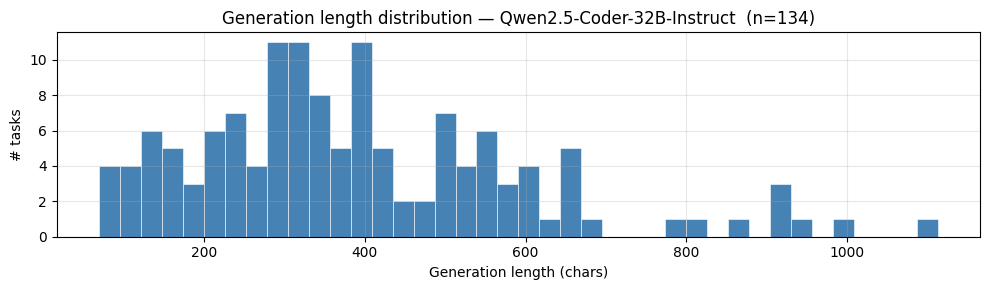

  min=69  median=346  max=1113  mean=391


In [7]:
import numpy as np
import matplotlib.pyplot as plt

gen_lengths = [len(r["generation"]) for r in results.values()]

fig, ax = plt.subplots(figsize=(10, 3))
ax.hist(gen_lengths, bins=40, color="steelblue", edgecolor="white", linewidth=0.4)
ax.set_xlabel("Generation length (chars)")
ax.set_ylabel("# tasks")
ax.set_title(f"Generation length distribution — {MODEL_SHORT}  (n={len(gen_lengths)})")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"  min={min(gen_lengths)}  median={int(np.median(gen_lengths))}  "
      f"max={max(gen_lengths)}  mean={np.mean(gen_lengths):.0f}")


In [8]:
from rich.markup import escape

# ── Inspect a single generation ──────────────────────────────────────────────
INSPECT_TASK = "bfs"  # change to any task name

if INSPECT_TASK not in results:
    rich_print(f"[red]{INSPECT_TASK!r} not found in results[/red]")
else:
    r = results[INSPECT_TASK]
    rich_print(f"[bold cyan]Task:[/bold cyan] {r['function_name']}")
    rich_print(
        f"[white]{r['prompt']}[/white][bright_yellow]{escape(r['generation'])}[/bright_yellow]"
    )


Task: bfs

<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical 
correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Implement breadth-first search graph traversal in Python. Write your code without any comments or explanations, 
just the implementation.<|im_end|>
<|im_start|>assistant
<code>
def bfs(graph, start):
    """Perform BFS on a graph starting from a given node."""
    visited = set()
    queue = [start]
    while queue:
        vertex = queue.pop(0)
        if vertex not in visited:
            visited.add(vertex)
            queue.extend([node for node in graph[vertex] if node not in visited])
    return visited
</code>

In [9]:
# ── Summary table: function name + first line of generation ──────────────────
from rich.table import Table

table = Table(title=f"All generations — {MODEL_SHORT}", show_lines=True, highlight=False)
table.add_column("Task", style="cyan", no_wrap=True)
table.add_column("Gen length", justify="right")
table.add_column("First line of generation", no_wrap=False, max_width=80)

for name, r in sorted(results.items()):
    first_line = r["generation"].strip().splitlines()[0] if r["generation"].strip() else "(empty)"
    table.add_row(name, str(len(r["generation"])), first_line)

rich_print(table)


                                   All generations — Qwen2.5-Coder-32B-Instruct                                    
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Task                           ┃ Gen length ┃ First line of generation                                          ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ add_binary                     │        492 │ Add two binary strings and return their sum as a binary           │
│                                │            │ string."""                                                        │
├────────────────────────────────┼────────────┼───────────────────────────────────────────────────────────────────┤
│ add_two_numbers_linked_list    │        580 │ Add two numbers represented by linked lists."""                   │
├────────────────────────────────┼────────────┼───────────────────────────────────────────────────────────────────┤
│ add_without_plus               │        153 │ Add two integers without using the '+' operator."""               │
├────────────────────────────────┼────────────┼───────────────────────────────────────────────────────────────────┤
│ atoi                           │        330 │ Converts a string to an integer."""                               │
├────────────────────────────────┼────────────┼───────────────────────────────────────────────────────────────────┤
│ basic_calculator               │        680 │ Evaluate a simple expression with +, -, and ()"""                 │
├────────────────────────────────┼────────────┼───────────────────────────────────────────────────────────────────┤
│ bellman_ford                   │        626 │ Bellman-Ford algorithm for finding shortest paths from start      │
│                                │            │ vertex to all other vertices."""                                  │
├────────────────────────────────┼────────────┼───────────────────────────────────────────────────────────────────┤
│ bfs                            │        315 │ Perform BFS on a graph starting from a given node."""             │
├────────────────────────────────┼────────────┼───────────────────────────────────────────────────────────────────┤
│ binary_search                  │        297 │ Binary search algorithm."""                                       │
├────────────────────────────────┼────────────┼───────────────────────────────────────────────────────────────────┤
│ binary_search_leftmost         │        389 │ Binary search for the leftmost occurrence of target in arr."""    │
├────────────────────────────────┼────────────┼───────────────────────────────────────────────────────────────────┤
│ bipartite_check                │        491 │ Check if the given graph is bipartite."""                         │
├────────────────────────────────┼────────────┼───────────────────────────────────────────────────────────────────┤
│ bubble_sort                    │        214 │ Sorts an array using bubble sort algorithm."""                    │
├────────────────────────────────┼────────────┼───────────────────────────────────────────────────────────────────┤
│ burst_balloons                 │        817 │ Given n balloons, indexed from 0 to n-1. Each balloon is painted  │
│                                │            │ with a number on it represented by array nums.                    │
├────────────────────────────────┼────────────┼───────────────────────────────────────────────────────────────────┤
│ caesar_cipher                  │        457 │ Encrypts the string s using a Caesar cipher with the given        │
│                                │            │ shift."""                                                         │
├────────────────────────────────┼────────────┼───────────────────────────────────────────────────────────────────┤
│ climbing_stairs                │        190 │ Fibonacc

In [10]:
print(r['generation'])

Given a binary tree, return the zigzag level order traversal of its nodes' values."""
    if not root:
        return []
    result, level, direction = [], [root], 1
    while level:
        next_level, vals = [], []
        for node in level:
            vals.append(node.val)
            if node.left:
                next_level.append(node.left)
            if node.right:
                next_level.append(node.right)
        result.append(vals[::direction])
        level = next_level
        direction *= -1
    return result
</code>


## Scope Identification — Intent Block Testing

Testing the AST-based `identify_intent_blocks` utility from `src/goals/scope_id.py`.

In [11]:
from src.goals.scope_id import (
    IntentBlock, identify_intent_blocks, get_blocks_at_char, extract_code_from_tags
)

In [12]:
bfs_code = """def bfs(graph, start):
    visited = set()
    queue = [start]
    while queue:
        vertex = queue.pop(0)
        if vertex not in visited:
            visited.add(vertex)
            queue.extend([node for node in graph[vertex] if node not in visited])
    return visited"""

root = identify_intent_blocks(bfs_code, level=5)


def print_tree(block, code=bfs_code, indent=0):
    label = f"  [{block.label}]" if block.label else ""
    snip = repr(
        code[block.char_start : min(block.char_end, block.char_start + 30)].replace(
            "\n", "\\n"
        )
    )
    print(
        " " * indent
        + f"{block.kind}  [{block.char_start}:{block.char_end}]  {snip}{label}"
    )
    for child in block.children:
        print_tree(child, code, indent + 2)


print_tree(root)

module  [0:276]  'def bfs(graph, start):\\n    vis'
  function  [0:276]  'def bfs(graph, start):\\n    vis'
    stmt  [27:42]  'visited = set()'
    stmt  [47:62]  'queue = [start]'
    while  [67:257]  'while queue:\\n        vertex = '
      stmt  [88:109]  'vertex = queue.pop(0)'
      if  [118:257]  'if vertex not in visited:\\n    '
        stmt  [156:175]  'visited.add(vertex)'
        stmt  [188:257]  'queue.extend([node for node in'
          listcomp  [201:256]  '[node for node in graph[vertex'
            compare_chain  [236:240]  'node'
            compare_chain  [248:255]  'visited'
    stmt  [262:276]  'return visited'


In [13]:
# Show innermost block kind at the first non-whitespace char of each line
lines = bfs_code.split("\n")
pos = 0
for i, line in enumerate(lines, 1):
    if line.strip():
        char_pos = pos + len(line) - len(line.lstrip())
        chain = get_blocks_at_char(root, char_pos)
        kinds = " > ".join(b.kind for b in chain)
        print(f"L{i:2d}: {kinds:60s}  {line}")
    pos += len(line) + 1

L 1: module > function                                             def bfs(graph, start):
L 2: module > function > stmt                                          visited = set()
L 3: module > function > stmt                                          queue = [start]
L 4: module > function > while                                         while queue:
L 5: module > function > while > stmt                                      vertex = queue.pop(0)
L 6: module > function > while > if                                        if vertex not in visited:
L 7: module > function > while > if > stmt                                     visited.add(vertex)
L 8: module > function > while > if > stmt                                     queue.extend([node for node in graph[vertex] if node not in visited])
L 9: module > function > stmt                                          return visited


In [14]:
# Load a real well-known-task generation and run scope identification
import json as _json
import pathlib

gen_files = sorted(RESULTS_DIR.glob('*.json'))
if gen_files:
    with open(gen_files[0]) as f:
        gen_data = _json.load(f)

    raw_gen = gen_data['generation']
    raw_prompt = gen_data['prompt']
    code_prefill = raw_prompt.split("<code>")[-1]
    code_generation = code_prefill + raw_gen
    if "</code>" in code_generation:
        code_generation = code_generation.split("</code>")[0]

    code = extract_code_from_tags(code_generation) or code_generation
    print(f"Task: {gen_data['function_name']}")
    print(f"Code ({len(code)} chars):\n{code}\n")

    try:
        gen_root = identify_intent_blocks(code, level=5)
        print_tree(gen_root, code)
    except SyntaxError as e:
        print(f'SyntaxError: {e}')
else:
    print('No generation files found in', RESULTS_DIR)

Task: add_binary
Code (515 chars):

def add_binary(a, b):
    """Add two binary strings and return their sum as a binary string."""
    max_len = max(len(a), len(b))
    a = a.zfill(max_len)
    b = b.zfill(max_len)
    result = ''
    carry = 0

    for i in range(max_len - 1, -1, -1):
        total = carry
        total += 1 if a[i] == '1' else 0
        total += 1 if b[i] == '1' else 0
        result = ('1' if total % 2 == 1 else '0') + result
        carry = 0 if total < 2 else 1

    if carry !=0 : result = '1' + result

    return result


module  [0:515]  '\\ndef add_binary(a, b):\\n    """'
  function  [1:514]  'def add_binary(a, b):\\n    """A'
    stmt  [27:96]  '"""Add two binary strings and '
    stmt  [101:130]  'max_len = max(len(a), len(b))'
    stmt  [135:155]  'a = a.zfill(max_len)'
    stmt  [160:180]  'b = b.zfill(max_len)'
    stmt  [185:196]  "result = ''"
    stmt  [201:210]  'carry = 0'
    for  [216:453]  'for i in range(max_len - 1, -1'
      stmt  [261:274]  '

In [15]:
# L5: BoolOp operands and Compare chains
expr_code = '''def check(s):
    return len(s) > 0 and s == s[::-1]'''

root5 = identify_intent_blocks(expr_code, level=5)
print_tree(root5, expr_code)

module  [0:52]  'def check(s):\\n    return len(s'
  function  [0:52]  'def check(s):\\n    return len(s'
    stmt  [18:52]  'return len(s) > 0 and s == s[:'
      boolop_operand  [25:35]  'len(s) > 0'
        compare_chain  [25:31]  'len(s)'
        compare_chain  [34:35]  '0'
      boolop_operand  [40:52]  's == s[::-1]'
        compare_chain  [40:41]  's'
        compare_chain  [45:52]  's[::-1]'


In [16]:
print(code)


def add_binary(a, b):
    """Add two binary strings and return their sum as a binary string."""
    max_len = max(len(a), len(b))
    a = a.zfill(max_len)
    b = b.zfill(max_len)
    result = ''
    carry = 0

    for i in range(max_len - 1, -1, -1):
        total = carry
        total += 1 if a[i] == '1' else 0
        total += 1 if b[i] == '1' else 0
        result = ('1' if total % 2 == 1 else '0') + result
        carry = 0 if total < 2 else 1

    if carry !=0 : result = '1' + result

    return result



In [17]:
gen_data['prompt']

'<|im_start|>system\nYou are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>\n<|im_start|>user\nImplement addition of two binary strings. Write your code without any comments or explanations, just the implementation.<|im_end|>\n<|im_start|>assistant\n<code>\ndef add_binary(a, b):\n    """'

## Intent Block Labeling

Label every `IntentBlock` in a code tree with a short intent phrase.

Two backends — selected by whether `mt` is passed:
- **Claude** (default, `mt=None`) — calls `ask_claude`; responses are disk-cached
- **Base LM** (`mt=<ModelandTokenizer>`) — batched greedy generation

In [21]:
from src.goals.scope_id import identify_intent_blocks, get_blocks_at_char
from src.goals.scope_labeler import (
    build_label_prompt,
    label_intent_block, label_all_blocks,
    save_labeled_tree, load_labeled_tree,
    tree_to_dict, dict_to_tree,
)

In [22]:
# Inspect prompt for a single block
bfs_code = '''def bfs(graph, start):
    visited = set()
    queue = [start]
    while queue:
        vertex = queue.pop(0)
        if vertex not in visited:
            visited.add(vertex)
            queue.extend([node for node in graph[vertex] if node not in visited])
    return visited'''

bfs_root = identify_intent_blocks(bfs_code, level=4)
target_block = bfs_root.children[0].children[0]  # visited = set()
print(repr(target_block))
print()
print(build_label_prompt(target_block, bfs_code))

IntentBlock(kind='stmt', span=(27, 42), label=None, n_children=0)

You are annotating Python code. Label the marked block with a short phrase.

Rules:
  1. One short phrase, 3–8 words.
  2. Describe the block's own operation — what it does, not why it exists relative to the surrounding function or algorithm.
  3. Start with a verb: "initialize X", "check if Y", "return the result".
  4. Do not reference the enclosing function's purpose or the overall algorithm context.
  5. No punctuation at the end.
  6. Do not use variable names from the code. Describe the abstract operation instead: e.g. "dequeue the next element" not "pop vertex from queue".

The block to label is marked with "# ← LABEL THIS" in the code below.
It is a stmt block starting at line 2.

```python
def bfs(graph, start):
    visited = set()  # ← LABEL THIS
    queue = [start]
    while queue:
        vertex = queue.pop(0)
        if vertex not in visited:
            visited.add(vertex)
            queue.extend([node fo

In [23]:
# Label a single block (Claude oracle, cached)
single_label = label_intent_block(bfs_root.children[0].children[0], bfs_code)
print('Label:', single_label)

# Or with the LM:
# single_label = label_intent_block(bfs_root.children[0].children[0], bfs_code, mt=mt)

2026-04-09 14:51:29 httpx DEBUG    load_ssl_context verify=True cert=None trust_env=True http2=False
2026-04-09 14:51:29 httpx DEBUG    load_verify_locations cafile='/disk/u/arnab/miniconda3/envs/goals/lib/python3.11/site-packages/certifi/cacert.pem'
2026-04-09 14:51:29 src.utils.oracle_llms DEBUG    found cached claude response for 5824edbbc8b5334f9eec7516cb1ddb62 - loading
Label: initialize an empty set for tracking visited nodes


In [24]:
# Label all blocks with Claude (default, mt=None)
bfs_root_labeled = identify_intent_blocks(bfs_code, level=5)
label_all_blocks(bfs_root_labeled, bfs_code, mt=mt, show_progress=True)

# Or with the loaded LM (batched):
# label_all_blocks(bfs_root_labeled, bfs_code, mt=mt, batch_size=8)


def print_labeled_tree(block, code, indent=0):
    label_str = f"  -> {block.label!r}" if block.label else ""
    snip = repr(code[block.char_start:block.char_start + 25].replace("\n", "\\n"))
    print(" " * indent + f"{block.kind}  {snip}{label_str}")
    for child in block.children:
        print_labeled_tree(child, code, indent + 2)


print_labeled_tree(bfs_root_labeled, bfs_code)

Output()

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
You have set `compile_config`, but we are unable to meet the criteria for compilation. Compilation will be skipped.


module  'def bfs(graph, start):\\n  '
  function  'def bfs(graph, start):\\n  '  -> 'initialize visited and queue'
    stmt  'visited = set()\\n    queue'  -> 'initialize visited set'
    stmt  'queue = [start]\\n    while'  -> 'enqueue the start element'
    while  'while queue:\\n        vert'  -> 'process elements in queue'
      stmt  'vertex = queue.pop(0)\\n   '  -> 'remove and return first element'
      if  'if vertex not in visited:'  -> 'check if element is unvisited'
        stmt  'visited.add(vertex)\\n     '  -> 'mark vertex as visited'
        stmt  'queue.extend([node for no'  -> 'enqueue unvisited neighbors'
          listcomp  '[node for node in graph[v'  -> 'enqueue unvisited neighbors'
            compare_chain  'node not in visited])\\n   '  -> 'extend queue with unvisited neighbors'
            compare_chain  'visited])\\n    return visi'  -> 'extend queue with unvisited neighbors'
    stmt  'return visited'  -> 'return the result'


In [ ]:
import json as _json
from src.goals.scope_id import extract_code_from_tags
from tqdm.auto import tqdm

LABEL_OUT_DIR = Path(DEFAULT_RESULTS_DIR) / "well-known-tasks" / "labels" / MODEL_SHORT / ORACLE_SHORT
LABEL_OUT_DIR.mkdir(parents=True, exist_ok=True)


gen_files = sorted(RESULTS_DIR.glob("*.json"))
print(f"Labeling {len(gen_files)} tasks  ->  {LABEL_OUT_DIR}")

errors = []
for gen_path in tqdm(gen_files[:5]):   # remove slice to run all
    out_path = LABEL_OUT_DIR / gen_path.name
    if out_path.exists():
        print(f"  skip (exists): {gen_path.stem}")
        continue

    with open(gen_path) as f:
        gen_data = _json.load(f)
    
    code_prefill = gen_data['prompt'].split("<code>")[-1]
    code_generation = code_prefill + gen_data["generation"]
    if "</code>" in code_generation:
        code_generation = code_generation.split("</code>")[0]

    code = extract_code_from_tags(code_generation) or code_generation

    try:
        task_root = identify_intent_blocks(code, level=5)
    except SyntaxError as e:
        print(f"  SyntaxError in {gen_path.stem}: {e}")
        errors.append(gen_path.stem)
        continue

    # Claude oracle (default, cached):
    label_all_blocks(task_root, code, show_progress=False)
    # LM oracle (batched):
    # label_all_blocks(task_root, code, mt=mt, batch_size=8, show_progress=False)

    save_labeled_tree(
        task_root, out_path, full_code=code,
        metadata={"function_name": gen_data["function_name"], "level": 4},
    )
    print(f"  saved: {gen_path.stem}")

print(f"Done. Errors: {errors or 'none'}")

Labeling 134 tasks  ->  /disk/u/arnab/Codes/Projects/goals/results/well-known-task-labeled-blocks/Qwen2.5-Coder-32B-Instruct


  0%|          | 0/5 [00:00<?, ?it/s]

  skip (exists): add_binary
  skip (exists): add_two_numbers_linked_list
  skip (exists): add_without_plus
  skip (exists): atoi
  skip (exists): basic_calculator
Done. Errors: none


In [27]:
# Load a saved labeled tree and inspect it
label_files = sorted(LABEL_OUT_DIR.glob("*.json"))
if label_files:
    loaded_root, loaded_code, loaded_meta = load_labeled_tree(label_files[0])
    print(f"Loaded: {loaded_meta.get('function_name', '?')}\n")
    print_labeled_tree(loaded_root, loaded_code)
else:
    print("No labeled trees found in", LABEL_OUT_DIR)

Loaded: add_binary

module  '\\ndef add_binary(a, b):\\n  '
  function  'def add_binary(a, b):\\n   '  -> 'Add two binary strings with carry logic'
    stmt  '"""Add two binary strings'  -> 'Initialize variables for binary addition'
    stmt  'max_len = max(len(a), len'  -> 'Find the maximum length of both strings'
    stmt  'a = a.zfill(max_len)\\n    '  -> 'Pad string with leading zeros'
    stmt  'b = b.zfill(max_len)\\n    '  -> 'Pad second string to match length'
    stmt  "result = ''\\n    carry = 0"  -> 'Initialize empty result string'
    stmt  'carry = 0\\n\\n    for i in r'  -> 'Initialize carry to zero'
    for  'for i in range(max_len - '  -> 'Iterate through digits from right to left'
      stmt  'total = carry\\n        tot'  -> 'Initialize total with carry value'
      stmt  "total += 1 if a[i] == '1'"  -> 'Add digit value from string a'
      stmt  "total += 1 if b[i] == '1'"  -> 'Add second bit to running total'
      stmt  "result = ('1' if total % "  -> 'Prepend com